## **Step 1: Project Introduction**
# 1.1 Problem Statement
Medical insurance charges vary among individuals depending on factors such as age, BMI, smoking habits and other personal characteristics.
This project aims to develop a machine learning model that analyzes these factors and predicts medical insurance charges for individuals. It also examines how different characteristics influence insurance costs.
# 1.2 Project Objectives
- Analyze medical insurance data.
- Identify factors influencing insurance charges.
- Develop a regression model to predict insurance charges.
- Evaluate the model's prediction performance.
- Generate predictions for new individuals.
# 1.3 Project Scope
The project uses the Medical Cost Personal Dataset . The model's performance will be evaluated using appropriate regression metrics.

## **Step 2: Data exploration**

In [1]:
# Loading libraries 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
# loading datasets
df = pd.read_csv('insurance.csv')

In [3]:
df.shape

(1338, 7)

In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [7]:
df["region"].nunique()

4

In [8]:
df['sex'].nunique()

2

In [9]:
df['smoker'].nunique()

2

In [10]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(1)

In [12]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [13]:
# removing the duplicated columns 
df = df.drop_duplicates()

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.shape

(1337, 7)

##  Step 3: Exploratory data analysis
3.1 Distribution of insurance charges

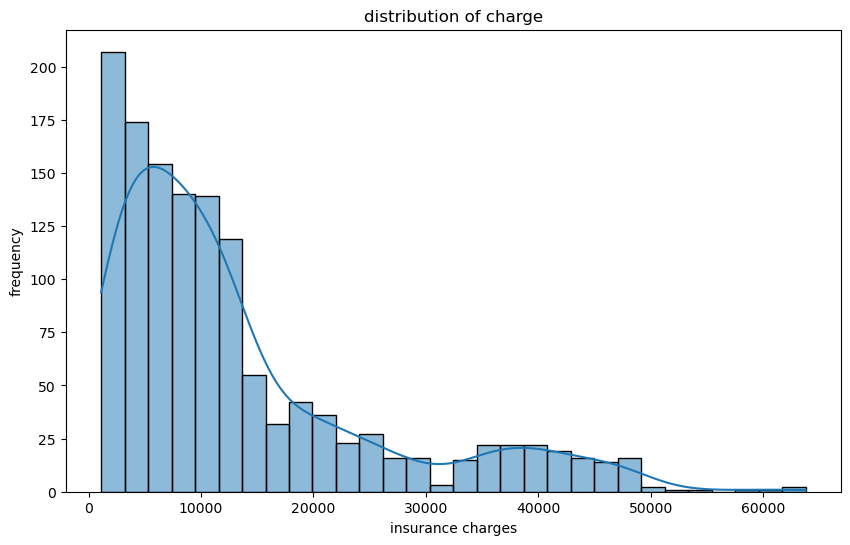

In [16]:
plt.figure(figsize=(10,6))
sns.histplot(df["charges"], bins=30, kde=True)
plt.title('distribution of charge')
plt.xlabel('insurance charges')
plt.ylabel('frequency')
plt.show()

The histogram shows that insurance charges are positively skewed (right-skewed). Most individuals have relatively low insurance charges, while a smaller number of individuals have considerably higher charges. This indicates that the charges are not normally distributed

3.2 Distribution of numerical features 

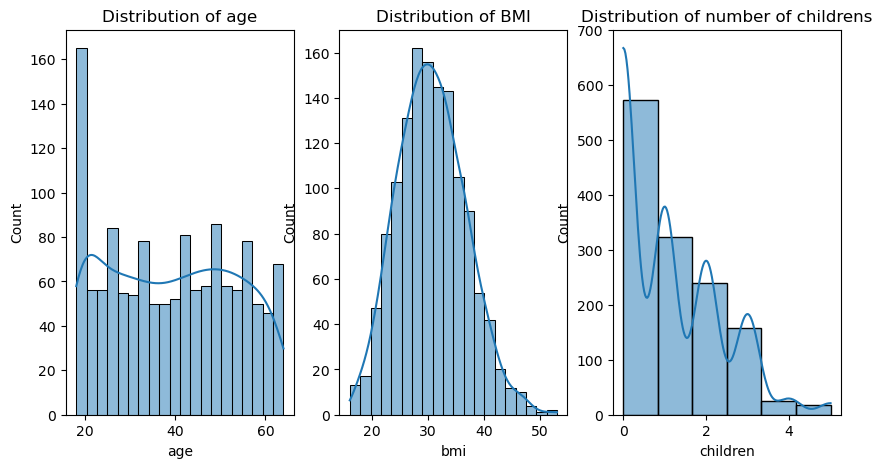

In [17]:
plt.figure(figsize=(10,5))

plt.subplot(1,3,1)
sns.histplot(df['age'], bins=20, kde=True)
plt.title('Distribution of age')

plt.subplot(1,3,2)
sns.histplot(df['bmi'], bins=20, kde=True)
plt.title('Distribution of BMI')

plt.subplot(1,3,3)
sns.histplot(df['children'], bins=6, kde=True)
plt.title('Distribution of number of childrens')

plt.show()

#Age: Individuals are distributed across a broad age range, with no single age group dominating the dataset.
#BMI: BMI values are concentrated around 30, with a roughly bell-shaped distribution.
#Children: Most individuals have no children, and the number of individuals decreases as the number of children increases.

3.3 Insurance charge by smoking status 

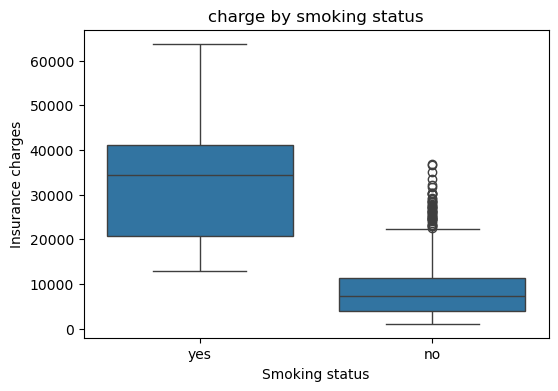

In [18]:
plt.figure(figsize=(6,4))
sns.boxplot(x='smoker', y='charges',data= df)
plt.title('charge by smoking status')
plt.xlabel('Smoking status')
plt.ylabel('Insurance charges')
plt.show()

The box plot shows a significant difference in insurance charges between smokers and non-smokers. Smokers generally have much higher insurance charges than non-smokers. This suggests that smoking status is an important factor associated with insurance charges.

3.4 Insurance charge by sex 

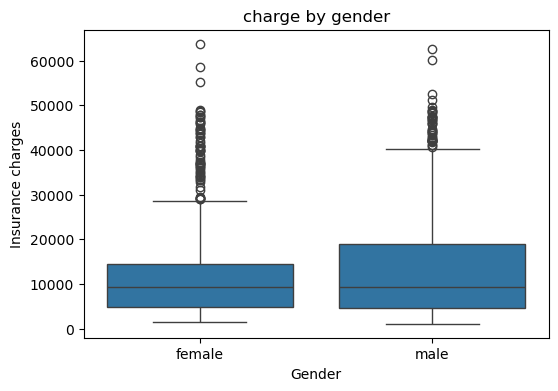

In [19]:
plt.figure(figsize=(6,4))
sns.boxplot(x='sex', y='charges',data= df)
plt.title('charge by gender')
plt.xlabel('Gender')
plt.ylabel('Insurance charges')
plt.show()

The box plot shows that insurance charges for males and females have broadly similar distributions. Although there are slight differences in their median charges, the distributions overlap considerably, suggesting that sex alone does not create a major difference in insurance charges in this dataset.

3.5 Insuarnce charge by Region

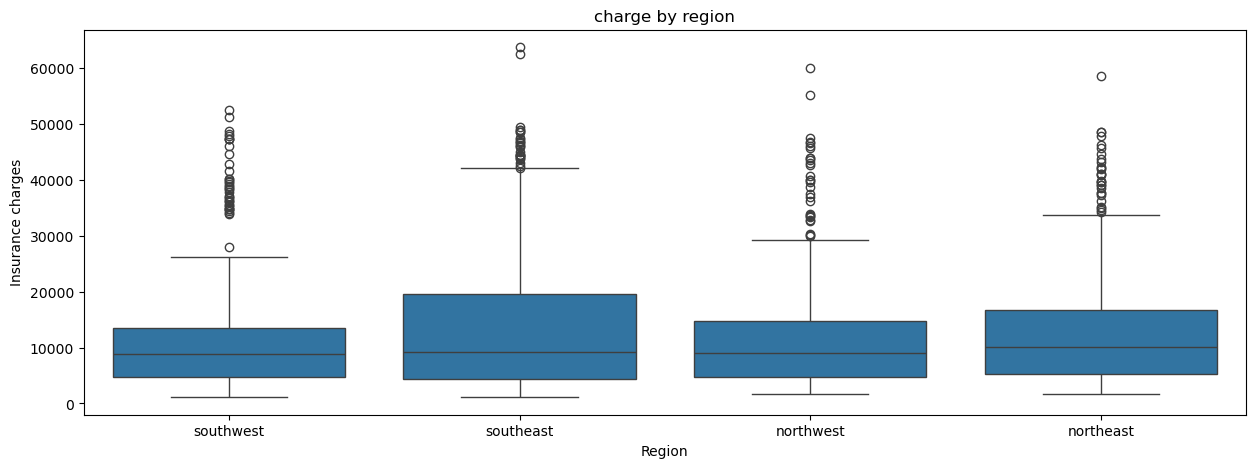

In [20]:
plt.figure(figsize=(15,5))
sns.boxplot(x='region', y='charges',data= df)
plt.title('charge by region')
plt.xlabel('Region')
plt.ylabel('Insurance charges')
plt.show()

The box plot shows that insurance charges vary slightly across the four regions. The Southeast region has a somewhat higher median charge, while the overall distributions are relatively similar. Therefore, region does not appear to create as large a difference as smoking status.

3.6 Insurance charge by Age


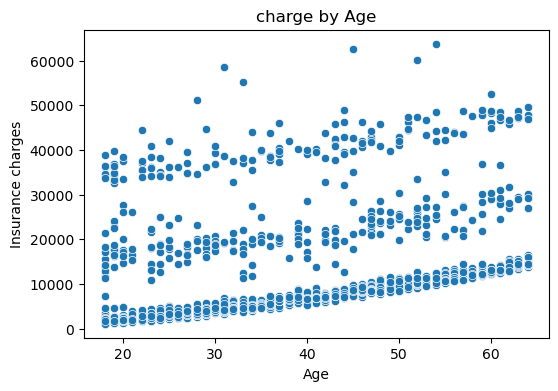

In [21]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='age', y='charges',data=df)
plt.title('charge by Age')
plt.xlabel('Age')
plt.ylabel('Insurance charges')
plt.show()

The scatter plot indicates a general positive relationship between age and insurance charges. As age increases, insurance charges tend to increase. The different bands of points also suggest that other factors, such as smoking status, may influence the charges.

3.7 Insurance charge by BMI


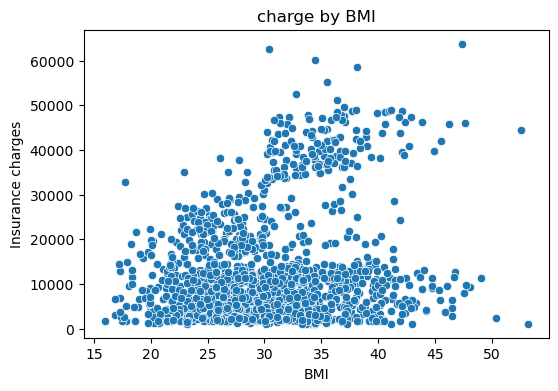

In [22]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='bmi', y='charges',data=df)
plt.title('charge by BMI')
plt.xlabel('BMI')
plt.ylabel('Insurance charges')
plt.show()

The scatter plot shows a relatively weak positive relationship between BMI and insurance charges overall. However, a separate group of individuals with higher charges is visible, suggesting that BMI may interact with other factors when influencing insurance charges.

3.8 Insuarnce charge by childrens

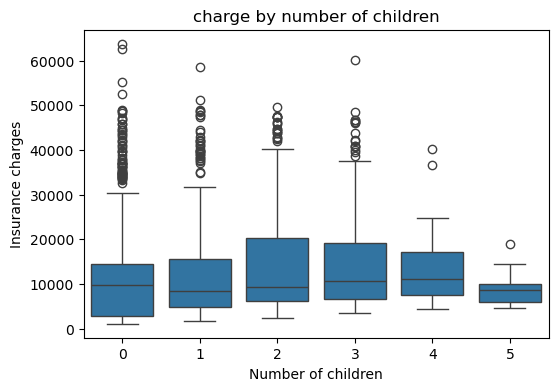

In [23]:
plt.figure(figsize=(6,4))
sns.boxplot(x='children', y='charges',data=df)
plt.title('charge by number of children')
plt.xlabel('Number of children')
plt.ylabel('Insurance charges')
plt.show()

The box plot shows that insurance charges are distributed across all categories of number of children. The median charges are broadly similar, although some variation exists between groups. Therefore, the number of children does not show a strong relationship with insurance charges in this graph.

3.9 correlation analysis

In [24]:
corr = df.corr(numeric_only=True)
corr

,age,bmi,children,charges
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389
charges,0.298308,0.198401,0.067389,1.000000


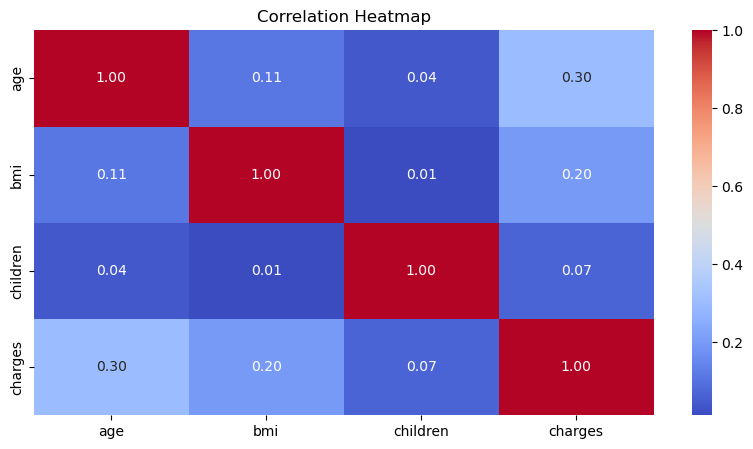

In [56]:
plt.figure(figsize=(10,5))
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

This indicates that age has the strongest linear correlation with insurance charges among the numerical variables considered. However, correlation does not establish causation.

# STEP 4: Data Preprocessing

4.1 Seperating dependent and independent variable

In [26]:
X = df.iloc[:, :-1].values
y = df.iloc[:,-1].values

In [27]:
X

array([[19, 'female', 27.9, 0, 'yes', 'southwest'],
       [18, 'male', 33.77, 1, 'no', 'southeast'],
       [28, 'male', 33.0, 3, 'no', 'southeast'],
       ...,
       [18, 'female', 36.85, 0, 'no', 'southeast'],
       [21, 'female', 25.8, 0, 'no', 'southwest'],
       [61, 'female', 29.07, 0, 'yes', 'northwest']],
      shape=(1337, 6), dtype=object)

In [28]:
y

array([16884.924 ,  1725.5523,  4449.462 , ...,  1629.8335,  2007.945 ,
       29141.3603], shape=(1337,))

4.2 Train Test Split 

In [29]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train,y_test = train_test_split(X,y, test_size=0.2)

In [30]:
print(X_train)

[[48 'male' 35.625 4 'no' 'northeast']
 [62 'female' 39.16 0 'no' 'southeast']
 [33 'male' 35.75 1 'yes' 'southeast']
 ...
 [61 'male' 35.86 0 'yes' 'southeast']
 [46 'male' 27.6 0 'no' 'southwest']
 [38 'male' 28.27 1 'no' 'southeast']]


In [31]:
print(X_test)

[[54 'male' 30.8 1 'yes' 'southeast']
 [21 'female' 33.63 2 'no' 'northwest']
 [54 'male' 32.775 0 'no' 'northeast']
 ...
 [18 'male' 23.085 0 'no' 'northeast']
 [22 'male' 32.11 0 'no' 'northwest']
 [27 'female' 20.045 3 'yes' 'northwest']]


In [32]:
print(y_train)

[10736.87075 13470.8044  38282.7495  ... 46599.1084  24603.04837
  5484.4673 ]


In [33]:
print(y_test)

[41999.52     3579.8287  10435.06525  5266.3656  36910.60803  1727.785
  4320.41085  6799.458    6593.5083   5649.715   11082.5772  19442.3535
  8604.48365 18310.742   10601.412    1984.4533   2217.46915 35491.64
  1727.54     4433.9159   4415.1588  11353.2276  10065.413   36219.40545
  9140.951    8277.523    5699.8375   9414.92    36898.73308  1728.897
  9800.8882   2730.10785 44423.803   11520.09985 10422.91665  2721.3208
  6184.2994  12950.0712   8891.1395   1253.936   12224.35085  5584.3057
  7740.337   43896.3763   2498.4144  42760.5022   5377.4578   7727.2532
  5373.36425  3756.6216  26926.5144   4133.64165  9487.6442  12646.207
 22218.1149   4463.2051   4753.6368   6059.173    7639.41745 38746.3551
  8534.6718   4738.2682   3393.35635 20149.3229  19361.9988   4337.7352
  1252.407    3736.4647  11381.3254   9724.53     6128.79745  8569.8618
 13063.883    8232.6388  55135.40209  9748.9106  12925.886    7804.1605
  1964.78     8582.3023   6082.405    1627.28245  9048.0273   3180.5

4.3 Encoding categorical variable

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [35]:
ct = ColumnTransformer(transformers=[('encoder',OneHotEncoder(),[1,4,5])],remainder='passthrough')
X_train = ct.fit_transform(X_train)
X_test  = ct.transform(X_test)

In [36]:
X_train

array([[0.0, 1.0, 1.0, ..., 48, 35.625, 4],
       [1.0, 0.0, 1.0, ..., 62, 39.16, 0],
       [0.0, 1.0, 0.0, ..., 33, 35.75, 1],
       ...,
       [0.0, 1.0, 0.0, ..., 61, 35.86, 0],
       [0.0, 1.0, 1.0, ..., 46, 27.6, 0],
       [0.0, 1.0, 1.0, ..., 38, 28.27, 1]], shape=(1069, 11), dtype=object)

In [37]:
X_test

array([[0.0, 1.0, 0.0, ..., 54, 30.8, 1],
       [1.0, 0.0, 1.0, ..., 21, 33.63, 2],
       [0.0, 1.0, 1.0, ..., 54, 32.775, 0],
       ...,
       [0.0, 1.0, 1.0, ..., 18, 23.085, 0],
       [0.0, 1.0, 1.0, ..., 22, 32.11, 0],
       [1.0, 0.0, 0.0, ..., 27, 20.045, 3]], shape=(268, 11), dtype=object)

4.4 Feature Scaling

In [38]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train[:,[8,9,10]] = sc.fit_transform(X_train[:,[8,9,10]])
X_test[:,[8,9,10]] = sc.transform(X_test[:,[8,9,10]])
print(X_train)
print(X_test)

[[0.0 1.0 1.0 ... 0.6308992658419215 0.8151395133492071
  2.4628415510709427]
 [1.0 0.0 1.0 ... 1.6291060966475246 1.3931506883804063
  -0.9049584081165698]
 [0.0 1.0 0.0 ... -0.4386080528783676 0.8355783809245678
  -0.06300841831969159]
 ...
 [0.0 1.0 0.0 ... 1.5578056087328387 0.8535645843908851
  -0.9049584081165698]
 [0.0 1.0 1.0 ... 0.4882982900125496 -0.49703578498894774
  -0.9049584081165698]
 [0.0 1.0 1.0 ... -0.08210561330493792 -0.38748345478501484
  -0.06300841831969159]]
[[0.0 1.0 0.0 ... 1.0587021933300371 0.026199224940285346
  -0.06300841831969159]
 [1.0 0.0 1.0 ... -1.2942139078545989 0.4889351868464512
  0.7789415714771867]
 [0.0 1.0 1.0 ... 1.0587021933300371 0.3491333326309836
  -0.9049584081165698]
 ...
 [0.0 1.0 1.0 ... -1.5081153715986566 -1.2352876818109753
  -0.9049584081165698]
 [0.0 1.0 1.0 ... -1.222913419939913 0.24039855713006497
  -0.9049584081165698]
 [1.0 0.0 0.0 ... -0.8664109803664832 -1.7323609412437466
  1.6208915612740649]]


# STEP 5: Model Development


# Linear regression

5.1 Training the linear regression model on training set

In [39]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


5.2 Predicting the test set results

In [40]:
y_pred = regressor.predict(X_test)
y_pred

array([35703.92496196,  5419.26071799, 13254.31650072,  5615.07114163,
       14750.25808296, -2222.0857514 ,  8786.77107477,  8213.47741148,
        6996.57027482,  8060.92551991, 10837.9342983 ,  7574.04397503,
        8851.08844404, 28057.35628171, 14959.22778341,  7283.82958267,
        6455.88658086, 29903.6465343 ,  4497.0118345 ,  7145.79782891,
        5290.53416613, 13148.26780589,  8343.07351527, 28956.53885182,
       12297.28011793,  8995.30775303,  9311.66061918, 10517.24706234,
       27187.31146302, -1944.67934096, 15203.44030941,  6529.35558784,
       36805.70168194, 10981.475563  , 10223.65146666,  3612.9381656 ,
        7195.80469829, 16536.42083026,  8296.42786244,  1778.52945137,
       12028.42660575,  9260.57286316, 11957.52356683, 36209.54937166,
        5792.65524772, 36312.13765525,  9060.24067699, 10881.39828282,
        8039.03832855,  3841.70713895, 35346.48135718,  4072.44445333,
       10949.34015141, 15351.71961717, 32309.78548158,  9363.32432594,
      

5.3 comparing the results

In [41]:
np.set_printoptions(precision=2)
print(np.concatenate((y_pred.reshape(len(y_pred),1),y_test.reshape(len(y_test),1)),1))

[[35703.92 41999.52]
 [ 5419.26  3579.83]
 [13254.32 10435.07]
 [ 5615.07  5266.37]
 [14750.26 36910.61]
 [-2222.09  1727.79]
 [ 8786.77  4320.41]
 [ 8213.48  6799.46]
 [ 6996.57  6593.51]
 [ 8060.93  5649.72]
 [10837.93 11082.58]
 [ 7574.04 19442.35]
 [ 8851.09  8604.48]
 [28057.36 18310.74]
 [14959.23 10601.41]
 [ 7283.83  1984.45]
 [ 6455.89  2217.47]
 [29903.65 35491.64]
 [ 4497.01  1727.54]
 [ 7145.8   4433.92]
 [ 5290.53  4415.16]
 [13148.27 11353.23]
 [ 8343.07 10065.41]
 [28956.54 36219.41]
 [12297.28  9140.95]
 [ 8995.31  8277.52]
 [ 9311.66  5699.84]
 [10517.25  9414.92]
 [27187.31 36898.73]
 [-1944.68  1728.9 ]
 [15203.44  9800.89]
 [ 6529.36  2730.11]
 [36805.7  44423.8 ]
 [10981.48 11520.1 ]
 [10223.65 10422.92]
 [ 3612.94  2721.32]
 [ 7195.8   6184.3 ]
 [16536.42 12950.07]
 [ 8296.43  8891.14]
 [ 1778.53  1253.94]
 [12028.43 12224.35]
 [ 9260.57  5584.31]
 [11957.52  7740.34]
 [36209.55 43896.38]
 [ 5792.66  2498.41]
 [36312.14 42760.5 ]
 [ 9060.24  5377.46]
 [10881.4   7

5.4 Model Evaluation

In [42]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
r2 = r2_score(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
print("r2:",r2)
print('MAE:',mae)
print('MSE:',mse)
print('RMSE:',rmse)

r2: 0.744026183573294
MAE: 3830.7211246709253
MSE: 33272718.65634257
RMSE: 5768.250918289059


The Linear Regression model achieved an R-squared value of approximately 0.744, indicating that it explains around 74.4% of the variation in insurance charges in the test dataset. The MAE indicates an average absolute prediction error of approximately 3,830.72.

# Decision Tree

In [43]:
# training the decision tree regression model
from sklearn.tree import DecisionTreeRegressor
regressor2 = DecisionTreeRegressor(random_state=0)
regressor2.fit(X_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [44]:
# predicting the test set result 
y_pred2 = regressor2.predict(X_test)
y_pred2

array([42303.69, 26018.95, 10923.93,  5272.18, 14007.22,  1731.68,
        3935.18, 24671.66,  6600.36,  5662.23, 11286.54,  4433.39,
        8603.82, 35147.53, 10602.39,  2217.6 ,  2217.6 , 37742.58,
        1725.55,  4433.39,  4889.04, 10976.25, 10436.1 , 36149.48,
       25992.82,  7789.64,  5709.16, 10115.01, 33750.29,  1731.68,
        9304.7 ,  2719.28, 44400.41,  9861.02, 10197.77,  1972.95,
        5926.85, 12557.61,  6837.37,  1242.82, 12222.9 ,  5846.92,
        8520.03, 40273.65,  2497.04, 42124.52,  6112.35,  7337.75,
        5478.04,  3757.84, 27037.91,  3561.89, 27346.04, 11881.36,
       23244.79,  4673.39,  4266.17,  5926.85,  7358.18, 39983.43,
        9500.57,  4462.72, 11272.33, 21659.93, 18259.22,  4719.52,
        1242.82,  2866.09, 24227.34, 10806.84,  5327.4 ,  8547.69,
       13470.86,  8233.1 , 37133.9 , 12592.53, 11946.63,  8283.68,
       27724.29,  8596.83,  6571.54,  1625.43,  9630.4 , 11884.05,
        7731.86,  9566.99,  4719.52,  3956.07, 27941.29, 48824

In [45]:
# comparing result
np.set_printoptions(precision=2)
print(np.concatenate((y_pred2.reshape(len(y_pred2),1),y_test.reshape(len(y_test),1)),1))

[[42303.69 41999.52]
 [26018.95  3579.83]
 [10923.93 10435.07]
 [ 5272.18  5266.37]
 [14007.22 36910.61]
 [ 1731.68  1727.79]
 [ 3935.18  4320.41]
 [24671.66  6799.46]
 [ 6600.36  6593.51]
 [ 5662.23  5649.72]
 [11286.54 11082.58]
 [ 4433.39 19442.35]
 [ 8603.82  8604.48]
 [35147.53 18310.74]
 [10602.39 10601.41]
 [ 2217.6   1984.45]
 [ 2217.6   2217.47]
 [37742.58 35491.64]
 [ 1725.55  1727.54]
 [ 4433.39  4433.92]
 [ 4889.04  4415.16]
 [10976.25 11353.23]
 [10436.1  10065.41]
 [36149.48 36219.41]
 [25992.82  9140.95]
 [ 7789.64  8277.52]
 [ 5709.16  5699.84]
 [10115.01  9414.92]
 [33750.29 36898.73]
 [ 1731.68  1728.9 ]
 [ 9304.7   9800.89]
 [ 2719.28  2730.11]
 [44400.41 44423.8 ]
 [ 9861.02 11520.1 ]
 [10197.77 10422.92]
 [ 1972.95  2721.32]
 [ 5926.85  6184.3 ]
 [12557.61 12950.07]
 [ 6837.37  8891.14]
 [ 1242.82  1253.94]
 [12222.9  12224.35]
 [ 5846.92  5584.31]
 [ 8520.03  7740.34]
 [40273.65 43896.38]
 [ 2497.04  2498.41]
 [42124.52 42760.5 ]
 [ 6112.35  5377.46]
 [ 7337.75  7

In [46]:
# model evaluation
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
r2 = r2_score(y_test,y_pred2)
mae = mean_absolute_error(y_test,y_pred2)
mse = mean_squared_error(y_test,y_pred2)
rmse = np.sqrt(mse)
print("r2:",r2)
print('MAE:',mae)
print('MSE:',mse)
print('RMSE:',rmse)

r2: 0.61510291201448
MAE: 3178.2719546641792
MSE: 50030791.03543659
RMSE: 7073.244731764666


The Decision Tree model achieved an R-squared value of approximately 0.615. Although its MAE is lower than that of Linear Regression, its RMSE and MSE are higher. This indicates that the model has larger prediction errors for some observations and does not perform as well overall as the other models.

# Random forest

In [47]:
# training the random forest regressor on the training set
from sklearn.ensemble import RandomForestRegressor
regressor3 = RandomForestRegressor(n_estimators=10,random_state=0)
regressor3.fit(X_train,y_train)

,n_estimators,10
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [48]:
# predicting the test set result 
y_pred3 = regressor3.predict(X_test)
y_pred3

array([44356.44, 23325.02, 11428.98,  5144.19, 14596.54,  1904.75,
        7646.61, 15644.4 , 11570.12,  5892.3 , 11492.78,  5924.74,
       16949.85, 21593.39, 10789.49,  5368.99,  2154.68, 37280.36,
        4580.31,  4397.53,  4543.68, 11766.79, 10357.72, 37993.23,
       14680.48,  8470.12,  6404.21,  9182.37, 34245.68,  7791.  ,
        9859.69,  4478.06, 45734.65, 17215.09, 10881.42,  4734.3 ,
        6139.09, 13477.69, 18586.  ,  3304.28, 12127.21,  5506.69,
        8055.38, 43014.91,  4111.82, 44541.63,  9829.87,  8808.69,
        5280.48,  3563.06, 27078.42,  3875.84, 15952.64, 11873.09,
       22929.39,  5996.25,  4503.26,  9164.91,  7317.13, 39477.7 ,
       16140.86,  6045.53,  9266.11, 20959.33, 19539.12,  5496.02,
        3127.78,  3548.85, 15175.41, 11528.51,  5591.98,  8782.17,
       14282.93, 12355.3 , 37318.15, 11601.64, 16760.59,  8363.99,
        1827.88,  9415.09,  6552.95,  1628.13,  9374.49,  7982.67,
        9951.2 , 14046.5 ,  6618.16,  4987.86, 17294.35, 49261

In [57]:
# model evaluation
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
r2 = r2_score(y_test,y_pred3)
mae = mean_absolute_error(y_test,y_pred3)
mse = mean_squared_error(y_test,y_pred3)
rmse = np.sqrt(mse)
print("r2:",r2)
print('MAE:',mae)
print('MSE:',mse)
print('RMSE:',rmse)

r2: 0.805303525143083
MAE: 2655.2119947675374
MSE: 25307592.478509482
RMSE: 5030.665212326247


The Random Forest model achieved an R-squared value of approximately 0.805, indicating that it explains around 80.5% of the variation in insurance charges in the test dataset. It also achieved the lowest MAE, MSE and RMSE among the three models, indicating better prediction performance.

In [59]:
# model comparision
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest'],
    'R2 Score': [0.7440, 0.6151, 0.8053],
    'MAE': [3830.72, 3178.27, 2655.21],
    'MSE': [33272718.66, 50030791.04, 25307592.48],
    'RMSE': [5768.25, 7073.24, 5030.67]
})

comparison

,Model,R2 Score,MAE,MSE,RMSE
0,Linear Regression,0.7440,3830.72,33272718.66,5768.25
1,Decision Tree,0.6151,3178.27,50030791.04,7073.24
2,Random Forest,0.8053,2655.21,25307592.48,5030.67


# Step 7: Making Predictions Using the Best Model.

In [50]:
new_customer = pd.DataFrame({
    'age': [30],
    'sex': ['female'],
    'bmi': [25.5],
    'children': [1],
    'smoker': ['no'],
    'region': ['southeast']
})

In [51]:
new_customer_encoded = ct.transform(new_customer)
print(new_customer_encoded)

[[ 1.   0.   1.   0.   0.   0.   1.   0.  30.  25.5  1. ]]


C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but OneHotEncoder was fitted without feature names
  warnings.warn(


In [52]:
new_customer_encoded[:, [8,9,10]] = sc.transform(
    new_customer_encoded[:, [8,9,10]]
)

In [53]:
# predicted using the best model(random forest)
predicted_charge = regressor3.predict(new_customer_encoded)
print(predicted_charge)

[4342.96]


The trained Random Forest model predicted an insurance charge of approximately 4,342.96 for the new customer based on the provided information. This demonstrates how the trained model can be used to estimate insurance charges for an individual with specified characteristics.

# STEP 8:Limitations of the Model

- Linear Regression produced a few negative predictions, even though insurance charges cannot be negative. This indicates a limitation of the model.
- The prediction accuracy depends on the quality and characteristics of the available dataset.
- The models were trained using a limited set of customer features. Including additional relevant factors may improve prediction performance.

# STEP 9: Conclusion

In this project, I developed a machine learning model to predict medical insurance charges using customer information such as age, sex, BMI, number of children, smoking status, and region.

I performed data exploration, exploratory data analysis, and data preprocessing, followed by training three regression models: Linear Regression, Decision Tree Regression, and Random Forest Regression.

The models were evaluated using R-squared, MAE, MSE, and RMSE. Among the three models, Random Forest Regression achieved the best performance, with an R-squared score of approximately 0.805 and an MAE of 2,655.21.

Finally, the selected model was used to predict the insurance charge for a new customer, demonstrating the application of machine learning in insurance charge prediction.

This project helped me understand the practical application of regression algorithms and model evaluation techniques in the insurance domain.